# Clasificación de Eventos Sísmicos Volcánicos usando CRNN

### Introducción

La actividad sísmica en zonas volcánicas representa un desafío importante para la seguridad de las poblaciones y la gestión de riesgos naturales. La detección y clasificación precisa de eventos sísmicos, como los de tipo VLP (Very Long Period), HB (Hibrid), LP (Long Period)  y VT (Volcano Tectonic), es fundamental para comprender los procesos internos de los volcanes y anticipar posibles erupciones o cambios en su comportamiento.

**Motivación del enfoque actual:**

En trabajos preliminares se exploró el uso de transfer learning con modelos preentrenados en voz humana (Wav2Vec2), obteniendo un accuracy de ~60%. Sin embargo, este enfoque presenta limitaciones importantes:
- Los modelos de voz están entrenados en dominios muy diferentes a señales sísmicas
- Los métodos clásicos de ML no capturan eficientemente la estructura temporal compleja
- Falta de técnicas de aumento de datos específicas para señales sísmicas

**Este trabajo propone:**

Implementar una arquitectura **CRNN (Convolutional-Recurrent Neural Network)** end-to-end para clasificar eventos sísmicos a partir de espectrogramas de mel. Esta arquitectura combina:
- **Capas convolucionales** para extraer características en el dominio tiempo-frecuencia
- **Data augmentation** específico para señales sísmicas
- **PyTorch Lightning** para entrenamiento robusto y reproducible

---


## Definición del Problema

Este proyecto corresponde a un problema de:

**Clasificación supervisada**

Entrada del modelo:

Señales sísmicas transformadas a representaciones tiempo-frecuencia
(por ejemplo espectrogramas o wavelets).

Salida del modelo:

- 0 → HB
- 1 → VLP
- 2 → VT
- 3 → LP

El modelo aprenderá patrones espectrales y temporales que permitan distinguir entre las cuatro diferentes clases.


In [1]:
# Librerías principales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Deep Learning
import torch
import torch.nn as nn
import torch.nn.functional as F

# PyTorch Lightning
import pytorch_lightning as pl
import torchmetrics
from torchinfo import summary
from pytorch_lightning.loggers import CSVLogger

# Utilidades
import random


c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}") 
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
print("Random seed configurado:", SEED)


PyTorch version: 2.7.1+cu118
CUDA available: True
CUDA device: NVIDIA GeForce GTX 1060 with Max-Q Design
Random seed configurado: 42


## Paso 1 — Carga y Exploración del Dataset

En esta sección se realiza la carga de los datos sísmicos y un análisis exploratorio inicial.

Objetivos:

- Cargar los datasets HB, VLP (VLP, VLP_TYPE_1, VLP_TYPE_2), VT y LP
- Unificarlos en un solo dataframe
- Convertir la señal almacenada como string a array numérico
- Analizar la distribución de clases
- Inspeccionar visualmente algunas señales

Este paso es fundamental para detectar problemas en los datos antes del entrenamiento del modelo.

In [ ]:
# Rutas del dataset
HB_PATH = "../data/processed/HB_IGEPN_1.csv"
LP_PATH = "../data/processed/LP_IGEPN_1.csv"
VLP_PATH = "../data/processed/VLP_2015_IGEPN_1.csv"
VLP_T1_PATH = "../data/processed/VLP_TYPE_1_2015_IGEPN_1.csv"
VLP_T2_PATH = "../data/processed/VLP_TYPE_2_2015_IGEPN_1.csv"
VT_PATH = "../data/processed/VT_IGEPN_1.csv"

# Cargar datasets
hb_df = pd.read_csv(HB_PATH)
lp_df = pd.read_csv(LP_PATH)
vlp_df = pd.read_csv(VLP_PATH)
vlp_t1_df = pd.read_csv(VLP_T1_PATH)
vlp_t2_df = pd.read_csv(VLP_T2_PATH)
vt_df = pd.read_csv(VT_PATH)

vlp_t1_df['Type'] = 'VLP'
vlp_t2_df['Type'] = 'VLP'

vlp_df = pd.concat(
    [vlp_df, vlp_t1_df, vlp_t2_df],
    ignore_index=True
)

# Dimensiones del dataset
print("HB shape:", hb_df.shape)
print("LP shape:", lp_df.shape)
print("VLP shape:", vlp_df.shape)
print("VT shape:", vt_df.shape)


HB shape: (170, 4)
LP shape: (4121, 4)
VLP shape: (181, 4)
VT shape: (2802, 4)


In [5]:
# Convertir la columna "Data" de string a array de numpy
import ast

def parse_signal(signal_str):
    return np.array(ast.literal_eval(signal_str), dtype=np.float32)

hb_df["signal"] = hb_df["Data"].apply(parse_signal)
lp_df["signal"] = lp_df["Data"].apply(parse_signal)
vlp_df["signal"] = vlp_df["Data"].apply(parse_signal)
vt_df["signal"] = vt_df["Data"].apply(parse_signal)


In [6]:
hb_lengths = hb_df["signal"].apply(len)
lp_lengths = lp_df["signal"].apply(len)
vt_lengths = vt_df["signal"].apply(len)
vlp_lengths = vlp_df["signal"].apply(len)

print("HB señal longitud promedio:", hb_lengths.mean())
print("VLP señal longitud promedio:", vlp_lengths.mean())
print("VT señal longitud promedio:", vt_lengths.mean())
print("LP señal longitud promedio:", lp_lengths.mean())

print("\nHB min/max:", hb_lengths.min(), hb_lengths.max())
print("VLP min/max:", vlp_lengths.min(), vlp_lengths.max())
print("VT min/max:", vt_lengths.min(), vt_lengths.max())
print("LP min/max:", lp_lengths.min(), lp_lengths.max())

hb_df["label"] = 0   # HB
vlp_df["label"] = 1  # VLP
vt_df["label"] = 2   # VT
lp_df["label"] = 3   # LP

dataset = pd.concat([hb_df, vlp_df, vt_df, lp_df], ignore_index=True)

print("\nDataset total:", dataset.shape)

HB señal longitud promedio: 4335.423529411764
VLP señal longitud promedio: 6796.933701657458
VT señal longitud promedio: 2949.4650249821557
LP señal longitud promedio: 4131.935695219607

HB min/max: 3026 8621
VLP min/max: 2941 12520
VT min/max: 2185 8765
LP min/max: 2265 20326

Dataset total: (7274, 6)


## Dataset

El dataset contiene eventos sísmicos etiquetados manualmente.

Distribución de clases:

- **HB:**  170  eventos
- **VLP:** 181  eventos
- **VT:**  2802 eventos
- **LP:**  4121 eventos

Total de señales:

**7274 eventos sísmicos**

Cada evento contiene:

- señal temporal
- frecuencia de muestreo
- etiqueta de clase

El dataset presenta **desbalance de clases**, por lo que será necesario aplicar técnicas de balanceo durante el entrenamiento.

Type
LP     4121
VT     2802
VLP     181
HB      170
Name: count, dtype: int64


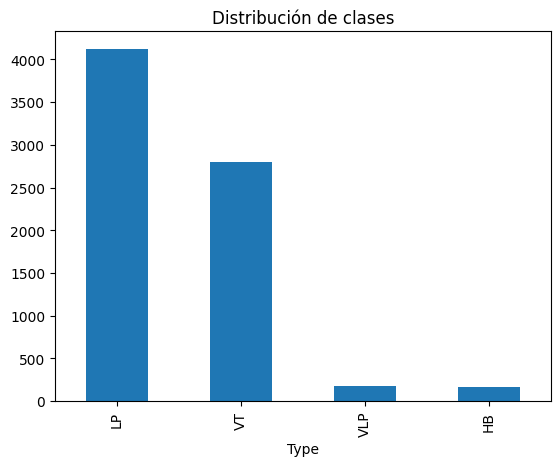

In [6]:
class_counts = dataset["Type"].value_counts()

print(class_counts)

class_counts.plot(kind="bar", title="Distribución de clases")
plt.show()


### Visualización de señales sísmicas

Se visualizarán algunas señales de cada clase para observar sus características.

Esto permite verificar:

- ruido
- amplitud
- forma temporal


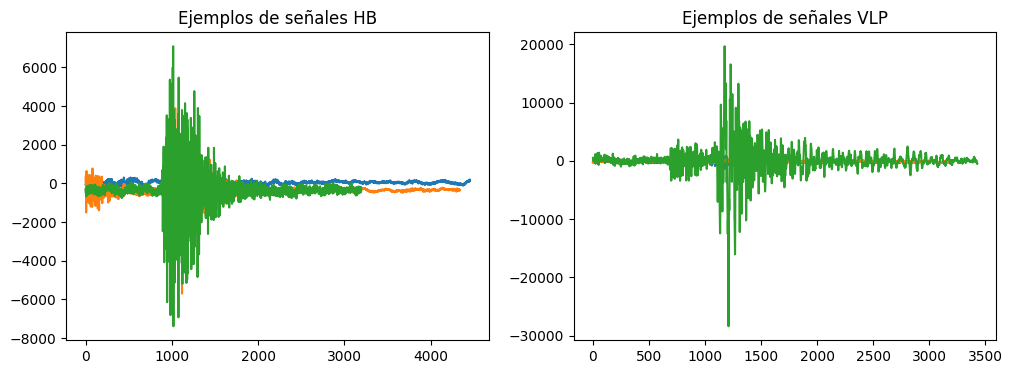

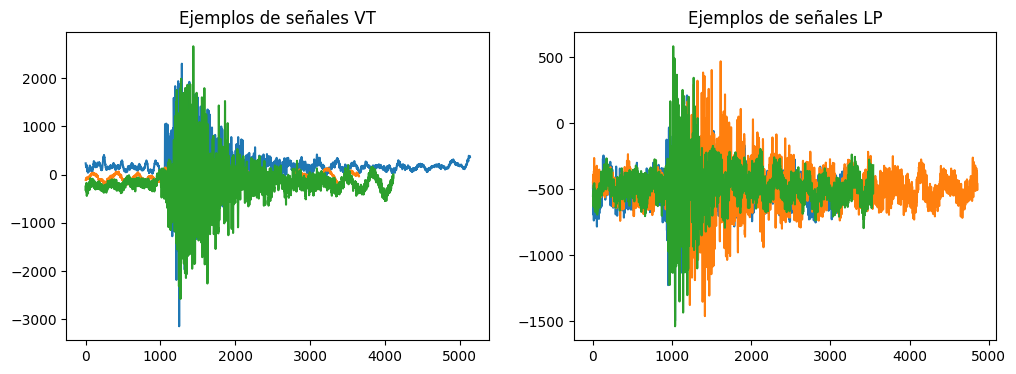

In [7]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
for i in range(3):
    plt.plot(dataset[dataset["label"] == 0].iloc[i]["signal"])
plt.title("Ejemplos de señales HB")

plt.subplot(1,2,2)
for i in range(3):
    plt.plot(dataset[dataset["label"] == 1].iloc[i]["signal"])
plt.title("Ejemplos de señales VLP")

plt.show()

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
for i in range(3):
    plt.plot(dataset[dataset["label"] == 2].iloc[i]["signal"])
plt.title("Ejemplos de señales VT")

plt.subplot(1,2,2)
for i in range(3):
    plt.plot(dataset[dataset["label"] == 3].iloc[i]["signal"])
plt.title("Ejemplos de señales LP")

plt.show()


### Conclusiones del análisis exploratorio

Hallazgos principales:

- El dataset contiene cuatro clases: HB, VLP, VT y LP.
- Existe desbalance de clases.
- Las señales sísmicas se encuentran almacenadas como series temporales.
---

## Paso 2 — Preprocesamiento de Señales Sísmicas

Las señales sísmicas presentan longitudes variables, lo cual impide utilizarlas directamente en redes neuronales.

Por lo tanto se aplicará el siguiente pipeline de preprocesamiento:

1. Normalización de la señal
2. Padding o truncamiento para obtener longitud fija
3. Conversión a representación tiempo–frecuencia mediante **Mel Spectrogram**
4. Conversión a **log-Mel spectrogram**

Esta representación es ampliamente utilizada en tareas de clasificación de audio y series temporales.


### Longitud objetivo de las señales

Para poder entrenar la red, todas las señales deben tener la misma longitud.

La longitud objetivo se selecciona a partir de la señal más larga observada en todas las clases:

- **HB:** 8621 muestras
- **VLP:** 12520 muestras
- **VT:** 8765 muestras
- **LP:** 20326 muestras

La señal más larga pertenece a la clase **LP**, con 20326 muestras.

Se utilizará una longitud objetivo de **20480 muestras** porque es el múltiplo de `HOP_LENGTH = 256` inmediatamente superior a 20326:

$$20480 = 80 \times 256$$

Esta elección permite conservar la totalidad de las señales del dataset, evita truncamientos y produce una cantidad entera de saltos temporales al calcular el espectrograma. Las señales más cortas se completarán mediante padding con ceros.

### Padding y truncamiento de señales

Se aplicará:

- **padding con ceros** si la señal es más corta
- **truncamiento** si la señal es más larga

Esto permite obtener tensores consistentes para el modelo.


In [8]:
import librosa
import librosa.display

TARGET_LENGTH = 20480

print("Longitud objetivo:", TARGET_LENGTH)

def fix_signal_length(signal, target_length=TARGET_LENGTH):
    if len(signal) > target_length:
        return signal[:target_length]

    if len(signal) < target_length:
        pad_size = target_length - len(signal)
        return np.pad(signal, (0, pad_size), mode="constant")
    
    return signal

dataset["signal_fixed"] = dataset["signal"].apply(fix_signal_length)
print("Ejemplo longitud:", len(dataset.iloc[0]["signal_fixed"]))

Longitud objetivo: 20480
Ejemplo longitud: 20480


### Normalización de señales

Antes de generar espectrogramas, se normalizará cada señal usando **z-score normalization**:

x_norm = (x - μ) / σ

Esto ayuda a estabilizar el entrenamiento de redes neuronales.


In [9]:
def normalize_signal(signal):
    mean = np.mean(signal)
    std = np.std(signal) + 1e-8
    return (signal - mean) / std

dataset["signal_norm"] = dataset["signal_fixed"].apply(normalize_signal)

### Generación de Mel Spectrogram

Las señales se transformarán a **Mel Spectrograms**, una representación tiempo–frecuencia que aproxima la percepción humana del sonido.

Posteriormente se aplicará una escala logarítmica para mejorar la representación de energía.


In [10]:
SAMPLE_RATE = 100 
N_FFT = 1024
HOP_LENGTH = 256
N_MELS = 64

def generate_mel_spectrogram(signal):
    mel_spec = librosa.feature.melspectrogram(
        y=signal,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )
    log_mel_spec = librosa.power_to_db(mel_spec, ref=np.max)
    return log_mel_spec

dataset["mel_spec"] = dataset["signal_norm"].apply(generate_mel_spectrogram)
print("Espectrogramas generados")

example_spec = dataset.iloc[0]["mel_spec"]
print("Shape del espectrograma:", example_spec.shape)

Espectrogramas generados
Shape del espectrograma: (64, 81)


### Visualización de Mel Spectrogram

Se visualizará un ejemplo para verificar que la transformación fue correcta.


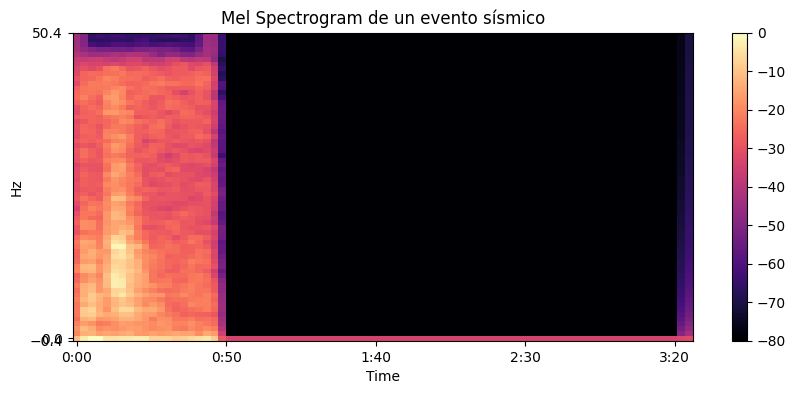

In [11]:
plt.figure(figsize=(10,4))

librosa.display.specshow(
    dataset.iloc[0]["mel_spec"],
    x_axis="time",
    y_axis="mel",
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH
)

plt.title("Mel Spectrogram de un evento sísmico")
plt.colorbar()
plt.show()

## Paso 3 - División del Dataset

Para evaluar correctamente el modelo es necesario dividir el dataset en tres subconjuntos:

- **Train:** entrenamiento del modelo
- **Validation:** ajuste de hiperparámetros
- **Test:** evaluación final

Se utilizará una división:

- **70% Train**
- **15% Validation**
- **15% Test**

Además se aplicará **Stratified Sampling** para mantener la proporción de las cuatro clases (HB, VLP, VT y LP) en cada subconjunto.

Esto evita sesgos en la evaluación del modelo.

In [12]:
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import Dataset, DataLoader

X = dataset["signal_norm"].values 
y = dataset["label"].values

print("Total muestras:", len(X))

# Primera división: Train y Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)
print("\nPrimera División")
print("Train+Val:", len(X_train_val))
print("Test:", len(X_test))

# Segunda división: Train y Validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.176,
    stratify=y_train_val,
    random_state=42
)
print("\nSegunda División")
print("Train:", len(X_train))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Total muestras: 7274

Primera División
Train+Val: 6182
Test: 1092

Segunda División
Train: 5093
Validation: 1089
Test: 1092


In [13]:
import pandas as pd

def class_distribution(labels):
    return pd.Series(labels).value_counts()

print("Train distribution")
print(class_distribution(y_train))

print("\nValidation distribution")
print(class_distribution(y_val))

print("\nTest distribution")
print(class_distribution(y_test))

Train distribution
3    2885
2    1962
1     127
0     119
Name: count, dtype: int64

Validation distribution
3    617
2    419
1     27
0     26
Name: count, dtype: int64

Test distribution
3    619
2    421
1     27
0     25
Name: count, dtype: int64


### Data Augmentation para señales sísmicas

Debido al tamaño reducido del dataset (240 señales), se aplican técnicas de **data augmentation específicas para señales sísmicas** con el objetivo de aumentar la variabilidad del conjunto de entrenamiento.

Las transformaciones aplicadas son:

* desplazamiento temporal (time shift)
* escalado de amplitud
* adición de ruido gaussiano

Estas transformaciones se aplican **solo durante el entrenamiento** para evitar contaminación del conjunto de validación y test.


In [14]:
import numpy as np
import random

def time_shift(signal, shift_max=0.1):
    shift = int(random.uniform(-shift_max, shift_max) * len(signal))
    return np.roll(signal, shift)

def amplitude_scaling(signal, scale_min=0.8, scale_max=1.2):
    scale = random.uniform(scale_min, scale_max)
    return signal * scale

def add_noise(signal, noise_level=0.005):
    noise = np.random.normal(0, noise_level, len(signal))
    return signal + noise

def augment_signal(signal):
    if random.random() < 0.5:
        signal = time_shift(signal)
    if random.random() < 0.5:
        signal = amplitude_scaling(signal)
    if random.random() < 0.5:
        signal = add_noise(signal)
    return signal

### Conversión de señal sísmica a Mel Spectrogram

Cada señal sísmica se transforma a una representación **tiempo-frecuencia** utilizando un **Mel Spectrogram**.

Además se calculan dos derivadas espectrales:

* **Delta** → captura cambios en el espectro
* **Delta-Delta** → captura aceleración espectral

Esto produce una representación **multi-canal (3 × Mel × Tiempo)** que mejora el aprendizaje del modelo CRNN.


In [15]:
import librosa
import numpy as np

def compute_mel_spectrogram(signal, sr=100, n_mels=64):
    # Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=signal,
        sr=sr,
        n_mels=n_mels
    )

    # Convertir a escala logarítmica
    mel_db = librosa.power_to_db(mel, ref=np.max)

    # Derivadas temporales
    delta = librosa.feature.delta(mel_db)
    delta2 = librosa.feature.delta(mel_db, order=2)

    # Stack de canales
    spectrogram = np.stack(
        [mel_db, delta, delta2],
        axis=0
    )

    return spectrogram

## Definición de PyTorch Dataset

In [16]:
class SeismicDataset(Dataset):
    def __init__(self, signals, labels, augment=False):
        self.signals = signals
        self.labels = labels
        self.augment = augment

    def __len__(self):
        return len(self.signals)

    def __getitem__(self, idx):
        signal = self.signals[idx]

        if self.augment:
            signal = augment_signal(signal)

        label = self.labels[idx]
        mel_spec = compute_mel_spectrogram(signal)
        mel_spec = torch.tensor(mel_spec, dtype=torch.float32)

        return mel_spec, torch.tensor(label, dtype=torch.long)

train_dataset = SeismicDataset(X_train, y_train, augment=True)
val_dataset = SeismicDataset(X_val, y_val, augment=False)
test_dataset = SeismicDataset(X_test, y_test, augment=False)

print("Datasets creados")

Datasets creados


## DataLoaders

In [17]:
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders listos\n")

for X_batch, y_batch in train_loader:
    print("Batch shape:", X_batch.shape)
    print("Labels shape:", y_batch.shape)
    break


DataLoaders listos

Batch shape: torch.Size([16, 3, 64, 41])
Labels shape: torch.Size([16])


## Paso 4 — Definición de la Arquitectura CRNN con LightningModule

Se implementará una arquitectura **CRNN (Convolutional Recurrent Neural Network)** envuelta en un **LightningModule**.

La arquitectura se divide en dos componentes:

**CRNN (arquitectura interna):**
- CNN → extracción de patrones espectrales en el Mel Spectrogram
- RNN (BiGRU) → modelar la evolución temporal de los eventos sísmicos

Esto permite capturar simultáneamente:
- Patrones de frecuencia
- Patrones temporales

**LightningCRNN (módulo de entrenamiento):**
- envuelve la arquitectura CRNN
- define `training_step`, `validation_step` y `test_step`
- gestiona el optimizador y scheduler desde `configure_optimizers`
- registra métricas automáticamente con `self.log()`


### Arquitectura del Modelo

El modelo se divide en dos niveles:

**1. CRNN (módulo interno - `nn.Module`)**
- CNN -> extracción de características en el espectrograma
- RNN (BiGRU) -> modelar dependencias temporales
- Clasificador -> cuatro logits, uno por clase: HB, VLP, VT y LP

**2. LightningCRNN (módulo de entrenamiento - `pl.LightningModule`)**
- envuelve CRNN
- define `training_step`, `validation_step`, `test_step`
- utiliza Focal Loss multiclase sobre logits
- define `configure_optimizers` con **Adam** + **CosineAnnealingWarmRestarts**
- registra métricas (loss, accuracy) en `metrics.csv` automáticamente

### Interpretación de la salida

La arquitectura **CRNN** produce un vector de cuatro logits. `CrossEntropyLoss` y la Focal Loss multiclase aplican internamente la normalización necesaria durante el entrenamiento; no se usa `sigmoid` ni `softmax` en `forward`.

La clase predicha se obtiene con `argmax`:

- `0` -> HB
- `1` -> VLP
- `2` -> VT
- `3` -> LP

In [18]:
NUM_CLASSES = 4
CLASS_NAMES = ["HB", "VLP", "VT", "LP"]

class CRNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()

        # CNN
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.pool = nn.MaxPool2d(2, 2)

        # RNN
        self.gru = nn.GRU(
            input_size=64 * 16,
            hidden_size=128,
            batch_first=True,
            bidirectional=True
        )

        # Clasificador multiclase
        self.fc1 = nn.Linear(256, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        # CNN
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        # shape esperado: (batch, 64, 16, T)
        batch, channels, freq, time = x.size()

        # Preparar para RNN
        x = x.permute(0, 3, 1, 2)
        x = x.contiguous().view(batch, time, channels * freq)

        # RNN
        x, _ = self.gru(x)

        # Usar último timestep
        x = x[:, -1, :]

        # Logits para CrossEntropyLoss
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)


print("Arquitectura CRNN multiclase definida")

Arquitectura CRNN multiclase definida


## Paso 5 - Entrenamiento del Modelo con PyTorch Lightning

En esta sección se entrena la arquitectura CRNN usando **PyTorch Lightning** para las cuatro clases: HB, VLP, VT y LP.

Se aplicarán buenas prácticas de entrenamiento:

- **Focal Loss multiclase** para compensar el desbalance entre clases
- **Adam optimizer** con weight decay
- **CosineAnnealingWarmRestarts** como scheduler
- **EarlyStopping** callback basado en `val_loss`
- **ModelCheckpoint** callback que guarda el mejor modelo

Lightning registra automáticamente las métricas (loss, accuracy) en `logs/crnn-seismic2/version_X/metrics.csv`.

In [19]:
# Hiperparámetros de entrenamiento
LEARNING_RATE = 0.001
NUM_EPOCHS    = 50
PATIENCE      = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print(f"LR: {LEARNING_RATE} | Épocas máx: {NUM_EPOCHS} | Paciencia: {PATIENCE}")


Device: cuda
LR: 0.001 | Épocas máx: 50 | Paciencia: 10


### Focal Loss para clases desbalanceadas

El dataset contiene cuatro clases con frecuencias muy diferentes: HB, VLP, VT y LP.

La Focal Loss multiclase enfatiza ejemplos difíciles. Adicionalmente puede recibir pesos por clase para compensar las clases menos frecuentes.

In [20]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce_loss)
        return ((1 - pt) ** self.gamma * ce_loss).mean()

### LightningCRNN — Módulo de Entrenamiento

El **LightningCRNN** es un `pl.LightningModule` que envuelve la arquitectura **CRNN** y elimina el boilerplate del loop manual.

Responsabilidades de cada método:

| Método | Función |
|---|---|
| `_shared_step` | calcula loss y predicciones (compartido entre train/val/test) |
| `training_step` | un paso de entrenamiento, registra `train_loss` y `train_acc` |
| `validation_step` | un paso de validación, registra `val_loss` y `val_acc` |
| `test_step` | evaluación final, registra `test_acc` |
| `configure_optimizers` | devuelve **Adam** + **CosineAnnealingWarmRestarts** |

In [21]:
class LightningCRNN(pl.LightningModule):
    def __init__(self, lr=0.001, num_epochs=50, class_weights=None):
        super().__init__()

        self.learning_rate = lr
        self.num_epochs = num_epochs

        # Arquitectura interna
        self.model = CRNN()
        class_weights = torch.tensor(class_weights, dtype=torch.float32) if class_weights is not None else None
        self.criterion = FocalLoss(alpha=class_weights, gamma=2.0)

        # Guardar hiperparámetros en hparams.yaml
        self.save_hyperparameters()

        # Métricas de accuracy multiclase
        self.train_acc = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES)
        self.val_acc = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES)
        self.test_acc = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES)

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch):
        features, true_labels = batch
        logits = self(features)
        true_labels = true_labels.long()
        loss = self.criterion(logits, true_labels)
        predicted_labels = torch.argmax(logits, dim=1)
        return loss, true_labels, predicted_labels

    def training_step(self, batch, batch_idx):
        loss, true_labels, predicted_labels = self._shared_step(batch)
        self.log("train_loss", loss, prog_bar=True)
        self.train_acc(predicted_labels, true_labels)
        self.log("train_acc", self.train_acc, on_epoch=True, on_step=False, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, true_labels, predicted_labels = self._shared_step(batch)
        self.log("val_loss", loss, prog_bar=True)
        self.val_acc(predicted_labels, true_labels)
        self.log("val_acc", self.val_acc, on_epoch=True, on_step=False, prog_bar=True)

    def test_step(self, batch, batch_idx):
        loss, true_labels, predicted_labels = self._shared_step(batch)
        self.test_acc(predicted_labels, true_labels)
        self.log("test_acc", self.test_acc, on_epoch=True, on_step=False)

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(
            self.parameters(),
            lr=self.learning_rate,
            weight_decay=5e-4,
            betas=(0.9, 0.999)
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer,
            T_0=10,
            T_mult=2,
            eta_min=1e-6
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "interval": "epoch",
                "frequency": 1
            }
        }

print("LightningCRNN multiclase definido")

LightningCRNN multiclase definido


In [23]:
# Instanciar modelo Lightning
lightning_model = LightningCRNN(
    lr=LEARNING_RATE,
    num_epochs=NUM_EPOCHS
)

summary(lightning_model, input_size=(1, 3, 64, 40))

Layer (type:depth-idx)                   Output Shape              Param #
LightningCRNN                            [1, 4]                    --
├─CRNN: 1-1                              [1, 4]                    --
│    └─Conv2d: 2-1                       [1, 32, 64, 40]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 64, 40]           64
│    └─MaxPool2d: 2-3                    [1, 32, 32, 20]           --
│    └─Conv2d: 2-4                       [1, 64, 32, 20]           18,496
│    └─BatchNorm2d: 2-5                  [1, 64, 32, 20]           128
│    └─MaxPool2d: 2-6                    [1, 64, 16, 10]           --
│    └─GRU: 2-7                          [1, 10, 256]              886,272
│    └─Linear: 2-8                       [1, 64]                   16,448
│    └─Dropout: 2-9                      [1, 64]                   --
│    └─Linear: 2-10                      [1, 4]                    260
Total params: 922,564
Trainable params: 922,564
Non-trainable params:

### Entrenamiento con Callbacks Lightning

Se configurarán dos callbacks:

- **EarlyStopping**: detiene el entrenamiento si `val_loss` no mejora durante `PATIENCE` épocas.
- **ModelCheckpoint**: guarda automáticamente el mejor modelo según `val_loss` en el directorio de logs.

El **Trainer** de Lightning gestiona el device, el loop de épocas y el logging sin código adicional.


In [24]:
import time

class SimpleEpochProgressCallback(pl.Callback):
    """Callback ligero para mostrar progreso por época sin overhead de progress bar."""

    def __init__(self):
        super().__init__()
        self.epoch_start_time = None

    def on_train_start(self, trainer, pl_module):
        """Imprimir configuración al inicio del entrenamiento."""
        train_dataloader = trainer.train_dataloader
        batch_size = getattr(train_dataloader, 'batch_size', 'N/A')
        num_batches = len(train_dataloader)
        print(f"\nConfiguración de Entrenamiento: Batch Size={batch_size}, Steps por Época={num_batches}\n")

    def on_train_epoch_start(self, trainer, pl_module):
        """Registrar tiempo de inicio de época."""
        self.epoch_start_time = time.time()

    def on_train_epoch_end(self, trainer, pl_module):
        """Imprimir resumen de una línea al final de cada época."""
        current_epoch = trainer.current_epoch + 1
        max_epochs = trainer.max_epochs
        epoch_time = time.time() - self.epoch_start_time if self.epoch_start_time else 0

        # Obtener métricas
        train_loss = trainer.callback_metrics.get('train_loss', None)
        val_loss = trainer.callback_metrics.get('val_loss', None)
        val_acc = trainer.callback_metrics.get('val_acc', None)

        # Construir salida
        parts = [f"Epoch {current_epoch}/{max_epochs}"]
        if train_loss is not None:
            parts.append(f"Train Loss: {train_loss:.4f}")
        if val_loss is not None:
            parts.append(f"Val Loss: {val_loss:.4f}")
        if val_acc is not None:
            parts.append(f"Val Acc: {val_acc:.4f}")
        parts.append(f"Time: {epoch_time:.2f}s")

        print(" | ".join(parts))

In [25]:
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint

logger = CSVLogger("logs/", name="crnn-seismic3")

epoch_progress = SimpleEpochProgressCallback()

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=PATIENCE,
    mode="min",
    verbose=True
)

checkpoint_cb = ModelCheckpoint(
    monitor="val_loss",
    mode="min",
    save_top_k=1,
    filename="best-epoch={epoch:02d}-val_loss={val_loss:.4f}-val_acc={val_acc:.4f}"
)

trainer = pl.Trainer(
    max_epochs=NUM_EPOCHS,
    callbacks=[early_stop, checkpoint_cb, epoch_progress],
    logger=logger,
    log_every_n_steps=1
)

print("Trainer configurado")


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores


Trainer configurado


In [26]:
trainer.fit(lightning_model, train_loader, val_loader)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ CRNN               │  922 K │ train │     0 │
│ 1 │ criterion │ FocalLoss          │      0 │ train │     0 │
│ 2 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 4 │ test_acc  │ MulticlassAccuracy │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 922 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 922 K                                                                                                
Total estimated model params size (MB): 3                                                                          
Modules in train mode: 14                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\rich\live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

... (66 outputs left out)

Epoch 49/50 | Train Loss: 0.0217 | Val Loss: 0.0923 | Val Acc: 0.9219 | Time: 37.26s

Metric val_loss improved by 0.004 >= min_delta = 0.0. New best score: 0.092


Epoch 50/50 | Train Loss: 0.0596 | Val Loss: 0.1035 | Val Acc: 0.9082 | Time: 36.67s

`Trainer.fit` stopped: `max_epochs=50` reached.


### Curvas de Entrenamiento

Se visualizarán las curvas de loss y accuracy generadas por el **CSVLogger** de PyTorch Lightning.

El archivo `metrics.csv` es guardado automáticamente en `logs/crnn-seismic2/version_X/`.


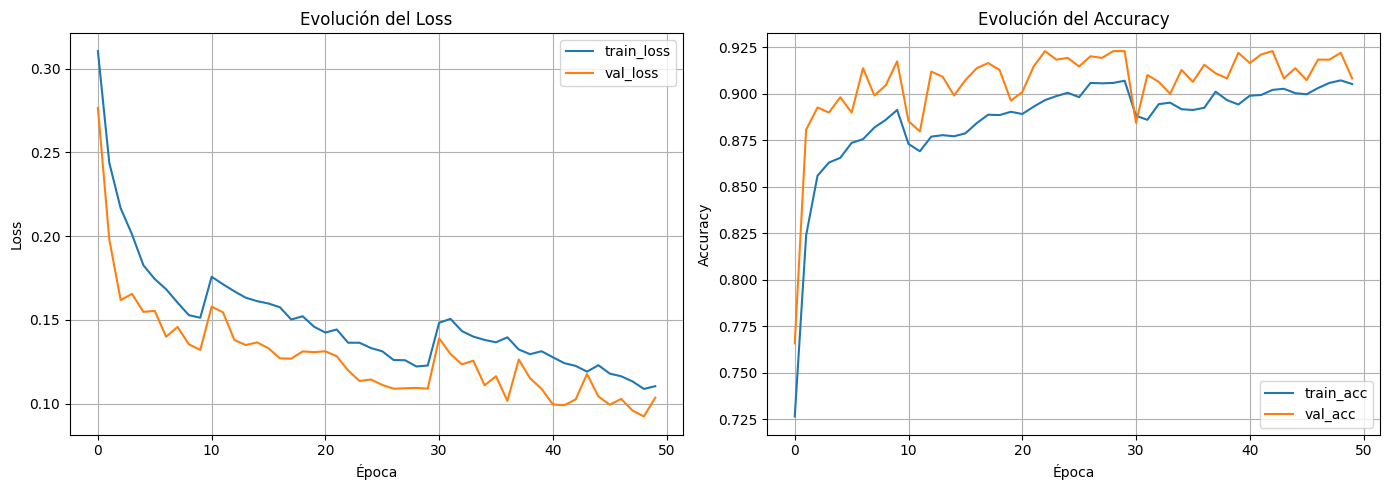


MÉTRICAS FINALES DE ENTRENAMIENTO
Épocas entrenadas: 50
Train Loss: 0.1104
Val Loss: 0.1035
Train Accuracy: 0.9052 (90.52%)
Val Accuracy: 0.9082 (90.82%)


In [27]:
# Cargar métricas del entrenamiento
metrics_path = f"{trainer.logger.log_dir}/metrics.csv"
metrics = pd.read_csv(metrics_path)

# Agregar métricas por época
aggreg_metrics = []
agg_col = "epoch"
for i, dfg in metrics.groupby(agg_col):
    agg = dict(dfg.mean())
    agg[agg_col] = i
    aggreg_metrics.append(agg)

df_metrics = pd.DataFrame(aggreg_metrics)

# Visualizar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
df_metrics[["train_loss", "val_loss"]].plot(
    ax=axes[0],
    grid=True,
    legend=True,
    xlabel="Época",
    ylabel="Loss",
    title="Evolución del Loss"
)
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")

# Accuracy
df_metrics[["train_acc", "val_acc"]].plot(
    ax=axes[1],
    grid=True,
    legend=True,
    xlabel="Época",
    ylabel="Accuracy",
    title="Evolución del Accuracy"
)
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")

plt.tight_layout()
plt.show()

# Mostrar métricas finales
print("\n" + "="*60)
print("MÉTRICAS FINALES DE ENTRENAMIENTO")
print("="*60)
last_epoch = df_metrics.iloc[-1]
print(f"Épocas entrenadas: {int(last_epoch['epoch']) + 1}")
print(f"Train Loss: {last_epoch['train_loss']:.4f}")
print(f"Val Loss: {last_epoch['val_loss']:.4f}")
print(f"Train Accuracy: {last_epoch['train_acc']:.4f} ({last_epoch['train_acc']*100:.2f}%)")
print(f"Val Accuracy: {last_epoch['val_acc']:.4f} ({last_epoch['val_acc']*100:.2f}%)")
print("="*60)

## Paso 6 - Evaluación del Modelo

En esta sección se evalúa el modelo entrenado utilizando el **test set**, que se mantuvo completamente separado durante el entrenamiento.

Se calcularán las siguientes métricas:

- Accuracy global
- Precision, recall y F1-score por clase
- Macro F1 y weighted F1
- Matriz de confusión de las cuatro clases

Estas métricas permiten evaluar el rendimiento del clasificador en la identificación de eventos sísmicos **HB**, **VLP**, **VT** y **LP**.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import seaborn as sns

best_model_path = checkpoint_cb.best_model_path
print("Mejor checkpoint:", best_model_path)

lightning_model = LightningCRNN.load_from_checkpoint(best_model_path)
lightning_model.eval()

print("Modelo cargado correctamente")


Mejor checkpoint: logs/crnn-seismic3\version_0\checkpoints\best-epoch=epoch=48-val_loss=val_loss=0.0923-val_acc=val_acc=0.9219.ckpt
Modelo cargado correctamente


In [29]:
y_true = []
y_pred = []

lightning_model = lightning_model.to(device)

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)
        logits = lightning_model(X_batch)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        y_pred.extend(preds)
        y_true.extend(y_batch.numpy())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("Accuracy global:", accuracy)
print("Precision macro:", precision)
print("Recall macro:", recall)
print("F1-score macro:", f1)

Accuracy global: 0.9093406593406593
Precision macro: 0.8239295125164691
Recall macro: 0.5994465613622633
F1-score macro: 0.64111514489172


In [30]:
print(classification_report(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
) )

              precision    recall  f1-score   support

          HB       0.67      0.08      0.14        25
         VLP       0.80      0.44      0.57        27
          VT       0.93      0.91      0.92       421
          LP       0.90      0.96      0.93       619

    accuracy                           0.91      1092
   macro avg       0.82      0.60      0.64      1092
weighted avg       0.90      0.91      0.90      1092



### Matriz de Confusión

La matriz de confusión permite observar:

- verdaderos positivos
- verdaderos negativos
- falsos positivos
- falsos negativos

Esto ayuda a identificar si el modelo presenta sesgos hacia alguna clase.


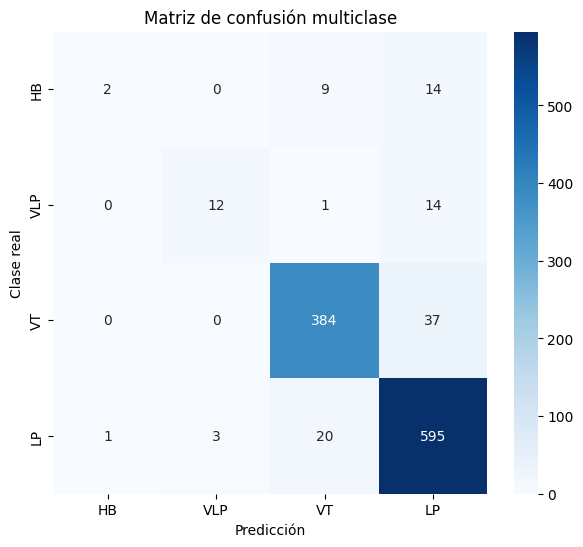

In [31]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de confusión multiclase")

plt.show()

In [16]:
NUM_CLASSES = 4
CLASS_NAMES = ["HB", "VLP", "VT", "LP"]

# Parámetros del espectrograma (cambio 4: se usan SIEMPRE estos valores)
SAMPLE_RATE = 100
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
TARGET_LENGTH = 20480  # 80 * 256

# Entrenamiento
BATCH_SIZE = 16
LEARNING_RATE = 1e-3
NUM_EPOCHS = 60
PATIENCE = 15
USE_SAMPLER = True  # WeightedRandomSampler además de los pesos en la loss

In [17]:
def normalize_signal(sig):
    return ((sig - sig.mean()) / (sig.std() + 1e-8)).astype(np.float32)


def pad_signal(sig, target=TARGET_LENGTH):
    sig = sig[:target]
    return np.pad(sig, (0, target - len(sig)), mode="constant")


signals_norm = [normalize_signal(s) for s in dataset["signal"]]
print("Longitud media:", np.mean([len(s) for s in signals_norm]).round(1))

Longitud media: 3747.5


In [18]:
import librosa
def time_stretch(sig, lo=0.95, hi=1.05):
    rate = random.uniform(lo, hi)
    n = max(2, int(len(sig) * rate))
    return np.interp(np.linspace(0, len(sig) - 1, n), np.arange(len(sig)), sig).astype(np.float32)


def add_noise(sig, snr_db_range=(10, 30)):
    snr_db = random.uniform(*snr_db_range)
    noise_std = np.sqrt(np.mean(sig ** 2) / (10 ** (snr_db / 10)))
    return (sig + np.random.normal(0, noise_std, len(sig))).astype(np.float32)


def augment_signal(sig):
    if random.random() < 0.5:
        sig = time_stretch(sig)
    if random.random() < 0.5:
        sig = add_noise(sig)
    return sig


def spec_augment(mel_db, length, n_freq_masks=2, f_max=8, n_time_masks=2, t_max=6):
    mel_db = mel_db.copy()
    fill = mel_db.mean()
    n_mels, n_frames = mel_db.shape
    valid = max(1, min(n_frames, length // HOP_LENGTH + 1))

    for _ in range(n_freq_masks):
        if random.random() < 0.5:
            f = random.randint(0, f_max)
            f0 = random.randint(0, n_mels - f)
            mel_db[f0:f0 + f, :] = fill

    for _ in range(n_time_masks):
        if random.random() < 0.5:
            t = random.randint(0, min(t_max, valid // 4))
            t0 = random.randint(0, max(0, valid - t))
            mel_db[:, t0:t0 + t] = fill
    return mel_db


def compute_features(sig, augment=False):
    """sig: señal normalizada SIN padding. Devuelve (3, N_MELS, T) y longitud real."""
    if augment:
        sig = augment_signal(sig)
    length = min(len(sig), TARGET_LENGTH)
    sig = pad_signal(sig)

    mel = librosa.feature.melspectrogram(
        y=sig, sr=SAMPLE_RATE, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)

    if augment:
        mel_db = spec_augment(mel_db, length)

    delta = librosa.feature.delta(mel_db)
    delta2 = librosa.feature.delta(mel_db, order=2)
    spec = np.stack([mel_db, delta, delta2], axis=0).astype(np.float32)
    return spec, length


spec_test, len_test = compute_features(signals_norm[0])
print("Shape espectrograma:", spec_test.shape, "| longitud real:", len_test)

Shape espectrograma: (3, 64, 161) | longitud real: 4456


In [20]:
y = dataset["label"].values

idx_all = np.arange(len(dataset))

idx_trval, idx_test = train_test_split(
    idx_all, test_size=0.15, stratify=y, random_state=42
)
idx_train, idx_val = train_test_split(
    idx_trval, test_size=0.176, stratify=y[idx_trval], random_state=42
)

print("Train:", len(idx_train), "| Val:", len(idx_val), "| Test:", len(idx_test))
print("Test por clase:", np.bincount(y[idx_test], minlength=NUM_CLASSES))  # debe ser [25, 27, 421, 619]

Train: 5093 | Val: 1089 | Test: 1092
Test por clase: [ 25  27 421 619]


In [21]:
counts = np.bincount(y[idx_train], minlength=NUM_CLASSES)
class_w = (1.0 / counts) ** 0.5
class_w = class_w / class_w.mean()
print("Conteo train:", dict(zip(CLASS_NAMES, counts)))
print("Pesos de clase:", dict(zip(CLASS_NAMES, class_w.round(2))))

Conteo train: {'HB': np.int64(119), 'VLP': np.int64(127), 'VT': np.int64(1962), 'LP': np.int64(2885)}
Pesos de clase: {'HB': np.float64(1.65), 'VLP': np.float64(1.6), 'VT': np.float64(0.41), 'LP': np.float64(0.34)}


In [22]:
class SeismicDataset(Dataset):
    def __init__(self, indices, augment=False):
        self.signals = [signals_norm[i] for i in indices]
        self.labels = y[indices]
        self.augment = augment
        # Sin augmentation los espectrogramas son fijos: se calculan una sola vez
        self.cache = None if augment else [compute_features(s) for s in self.signals]

    def __len__(self):
        return len(self.signals)

    def __getitem__(self, i):
        if self.cache is not None:
            spec, length = self.cache[i]
        else:
            spec, length = compute_features(self.signals[i], augment=True)
        return (
            torch.from_numpy(spec),
            torch.tensor(int(length), dtype=torch.long),
            torch.tensor(int(self.labels[i]), dtype=torch.long),
        )


train_dataset = SeismicDataset(idx_train, augment=True)
val_dataset = SeismicDataset(idx_val, augment=False)
test_dataset = SeismicDataset(idx_test, augment=False)

if USE_SAMPLER:
    sample_w = class_w[y[idx_train]]
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(sample_w, dtype=torch.double),
        num_samples=len(idx_train),
        replacement=True,
    )
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler)
else:
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

xb, lb, yb = next(iter(train_loader))
print("Batch:", xb.shape, lb.shape, yb.shape)
print("Clases en el primer batch:", np.bincount(yb.numpy(), minlength=NUM_CLASSES))

Batch: torch.Size([16, 3, 64, 161]) torch.Size([16]) torch.Size([16])
Clases en el primer batch: [1 3 7 5]


In [23]:
class CRNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, n_mels=N_MELS, hop=HOP_LENGTH):
        super().__init__()
        self.hop = hop

        self.input_bn = nn.BatchNorm2d(3)
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2, 2)

        self.gru = nn.GRU(
            input_size=64 * (n_mels // 4),
            hidden_size=128,
            batch_first=True,
            bidirectional=True,
        )

        self.fc1 = nn.Linear(256 * 2, 64)  # mean + max
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x, lengths):
        x = self.input_bn(x)
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        b, c, f, t = x.shape
        x = x.permute(0, 3, 1, 2).contiguous().view(b, t, c * f)

        # Frames válidos tras las dos capas de pooling (cada una divide el tiempo entre 2)
        frames = ((lengths // self.hop) + 1) // 4
        frames = torch.clamp(frames, min=1, max=t)

        packed = pack_padded_sequence(
            x, frames.cpu(), batch_first=True, enforce_sorted=False
        )
        out, _ = self.gru(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=t)

        mask = (torch.arange(t, device=x.device)[None, :] < frames[:, None]).unsqueeze(-1)
        mean_pool = (out * mask).sum(dim=1) / mask.sum(dim=1)
        max_pool = out.masked_fill(~mask, float("-inf")).max(dim=1).values

        h = torch.cat([mean_pool, max_pool], dim=1)
        h = F.relu(self.fc1(h))
        h = self.dropout(h)
        return self.fc2(h)

In [24]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.register_buffer("alpha", alpha)
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()


class LightningCRNN(pl.LightningModule):
    def __init__(self, lr=1e-3, class_weights=None):
        super().__init__()
        self.save_hyperparameters()
        self.learning_rate = lr

        self.model = CRNN()
        w = torch.tensor(class_weights, dtype=torch.float32) if class_weights is not None else None
        self.criterion = FocalLoss(alpha=w, gamma=2.0)

        self.train_acc = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES)
        self.val_acc = torchmetrics.Accuracy(task="multiclass", num_classes=NUM_CLASSES)
        self.val_f1 = torchmetrics.F1Score(task="multiclass", num_classes=NUM_CLASSES, average="macro")
        self.test_f1 = torchmetrics.F1Score(task="multiclass", num_classes=NUM_CLASSES, average="macro")

    def forward(self, x, lengths):
        return self.model(x, lengths)

    def _shared_step(self, batch):
        x, lengths, labels = batch
        logits = self(x, lengths)
        loss = self.criterion(logits, labels)
        return loss, labels, torch.argmax(logits, dim=1)

    def training_step(self, batch, batch_idx):
        loss, labels, preds = self._shared_step(batch)
        self.log("train_loss", loss, on_epoch=True, on_step=False, prog_bar=True)
        self.train_acc(preds, labels)
        self.log("train_acc", self.train_acc, on_epoch=True, on_step=False)
        return loss

    def validation_step(self, batch, batch_idx):
        loss, labels, preds = self._shared_step(batch)
        self.log("val_loss", loss, on_epoch=True, prog_bar=True)
        self.val_acc(preds, labels)
        self.val_f1(preds, labels)
        self.log("val_acc", self.val_acc, on_epoch=True, on_step=False)
        self.log("val_f1", self.val_f1, on_epoch=True, on_step=False, prog_bar=True)

    def test_step(self, batch, batch_idx):
        _, labels, preds = self._shared_step(batch)
        self.test_f1(preds, labels)
        self.log("test_f1", self.test_f1, on_epoch=True, on_step=False)

    def configure_optimizers(self):
        optimizer = torch.optim.Adam(
            self.parameters(), lr=self.learning_rate, weight_decay=5e-4
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
            optimizer, T_0=10, T_mult=2, eta_min=1e-6
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"},
        }


lightning_model = LightningCRNN(lr=LEARNING_RATE, class_weights=class_w.tolist())

In [25]:
logger = CSVLogger("logs/", name="crnn-seismic-v2")

early_stop = EarlyStopping(monitor="val_f1", mode="max", patience=PATIENCE, verbose=True)
checkpoint_cb = ModelCheckpoint(
    monitor="val_f1",
    mode="max",
    save_top_k=1,
    filename="best-{epoch:02d}-{val_f1:.4f}",
    auto_insert_metric_name=False,
)

trainer = pl.Trainer(
    max_epochs=NUM_EPOCHS,
    min_epochs=20,
    callbacks=[early_stop, checkpoint_cb],
    logger=logger,
    log_every_n_steps=10,
)

trainer.fit(lightning_model, train_loader, val_loader)
print("Mejor checkpoint:", checkpoint_cb.best_model_path)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ CRNN               │  938 K │ train │     0 │
│ 1 │ criterion │ FocalLoss          │      0 │ train │     0 │
│ 2 │ train_acc │ MulticlassAccuracy │      0 │ train │     0 │
│ 3 │ val_acc   │ MulticlassAccuracy │      0 │ train │     0 │
│ 4 │ val_f1    │ MulticlassF1Score  │      0 │ train │     0 │
│ 5 │ test_f1   │ MulticlassF1Score  │      0 │ train │     0 │
└───┴───────────┴────────────────────┴────────┴───────┴───────┘

Trainable params: 938 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 938 K                                                                                                
Total estimated model params size (MB): 3                                                                          
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\rich\live.py:256: UserWarning: install 
"ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

c:\Users\steve\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_lightning\trainer\connectors\data_
connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing 
the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.

Metric val_f1 improved. New best score: 0.146
Metric val_f1 improved by 0.002 >= min_delta = 0.0. New best score: 0.149
Metric val_f1 improved by 0.065 >= min_delta = 0.0. New best score: 0.214
Metric val_f1 improved by 0.229 >= min_delta = 0.0. New best score: 0.442
Metric val_f1 improved by 0.021 >= min_delta = 0.0. New best score: 0.464
Metric val_f1 improved by 0.015 >= min_delta = 0.0. New best score: 0.479
Metric val_f1 improved by 0.018 >= min_delta = 0.0. New best score: 0.497
Metric val_f1 improved by 0.037 >= min_delta = 0.0. New best score: 0.535
Metric val_f1 improved by 0.015 >= min_delta = 0.0. New best score: 0.550
Monitored metric val_f1 did not improve in the last 15 records. Best score: 0.550. Signaling Trainer to stop.


Mejor checkpoint: logs/crnn-seismic-v2\version_3\checkpoints\best-27-0.5498.ckpt


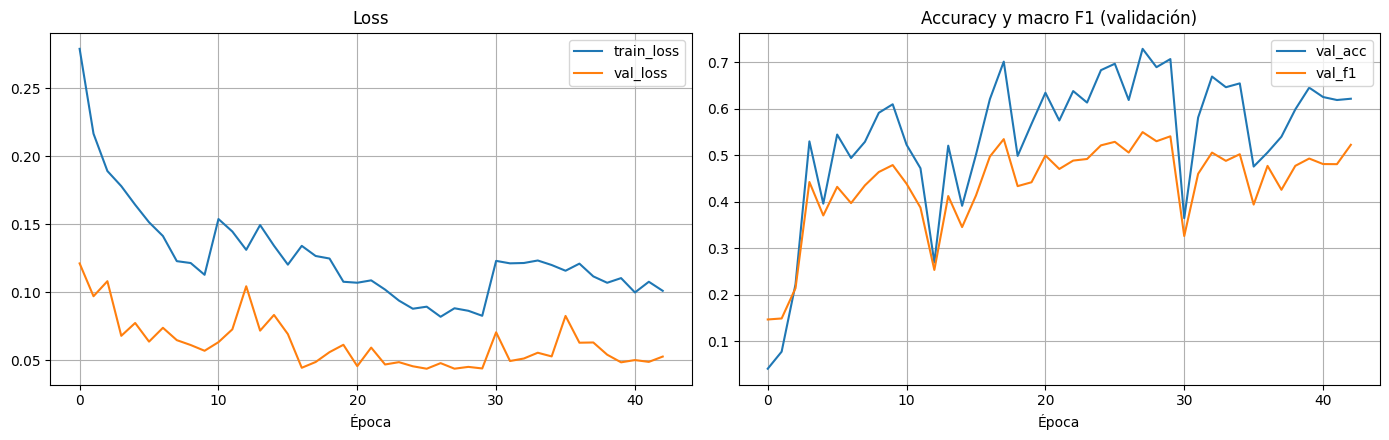

In [26]:
# Curvas de entrenamiento
metrics = pd.read_csv(f"{trainer.logger.log_dir}/metrics.csv")
df_m = metrics.groupby("epoch").mean(numeric_only=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
df_m[["train_loss", "val_loss"]].plot(ax=axes[0], grid=True, title="Loss")
df_m[["val_acc", "val_f1"]].plot(ax=axes[1], grid=True, title="Accuracy y macro F1 (validación)")
for ax in axes:
    ax.set_xlabel("Época")
plt.tight_layout()
plt.show()

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LightningCRNN.load_from_checkpoint(checkpoint_cb.best_model_path).to(device).eval()

y_true, y_pred = [], []
with torch.no_grad():
    for x, lengths, labels in test_loader:
        logits = model(x.to(device), lengths.to(device))
        y_pred.extend(torch.argmax(logits, dim=1).cpu().numpy())
        y_true.extend(labels.numpy())

print(classification_report(
    y_true, y_pred, labels=range(NUM_CLASSES), target_names=CLASS_NAMES, zero_division=0
))

              precision    recall  f1-score   support

          HB       0.10      0.72      0.17        25
         VLP       0.19      0.96      0.32        27
          VT       0.91      0.79      0.85       421
          LP       0.98      0.64      0.78       619

    accuracy                           0.71      1092
   macro avg       0.55      0.78      0.53      1092
weighted avg       0.91      0.71      0.78      1092



In [29]:
BASELINE_CM = np.array([
    [2,  0,   9,  14],
    [0, 12,   1,  14],
    [0,  0, 384,  37],
    [1,  3,  20, 595],
])
cm_new = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))


def metrics_from_cm(cm):
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(axis=0), 1)
    rec = tp / np.maximum(cm.sum(axis=1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    acc = tp.sum() / cm.sum()
    return prec, rec, f1, acc


p0, r0, f0, a0 = metrics_from_cm(BASELINE_CM)
p1, r1, f1_, a1 = metrics_from_cm(cm_new)

summary = pd.DataFrame({
    "Accuracy": [a0, a1],
    "Recall macro": [r0.mean(), r1.mean()],
    "F1 macro": [f0.mean(), f1_.mean()],
}, index=["v1 (original)", "v2 (mejorado)"]).round(3)
display(summary)

per_class = pd.DataFrame({
    "Recall v1": r0, "Recall v2": r1, "F1 v1": f0, "F1 v2": f1_,
}, index=CLASS_NAMES).round(3)
display(per_class)

,Accuracy,Recall macro,F1 macro
v1 (original),0.909,0.599,0.641
v2 (mejorado),0.710,0.779,0.529


,Recall v1,Recall v2,F1 v1,F1 v2
HB,0.080,0.720,0.143,0.171
VLP,0.444,0.963,0.571,0.323
VT,0.912,0.789,0.920,0.847
LP,0.961,0.645,0.930,0.776


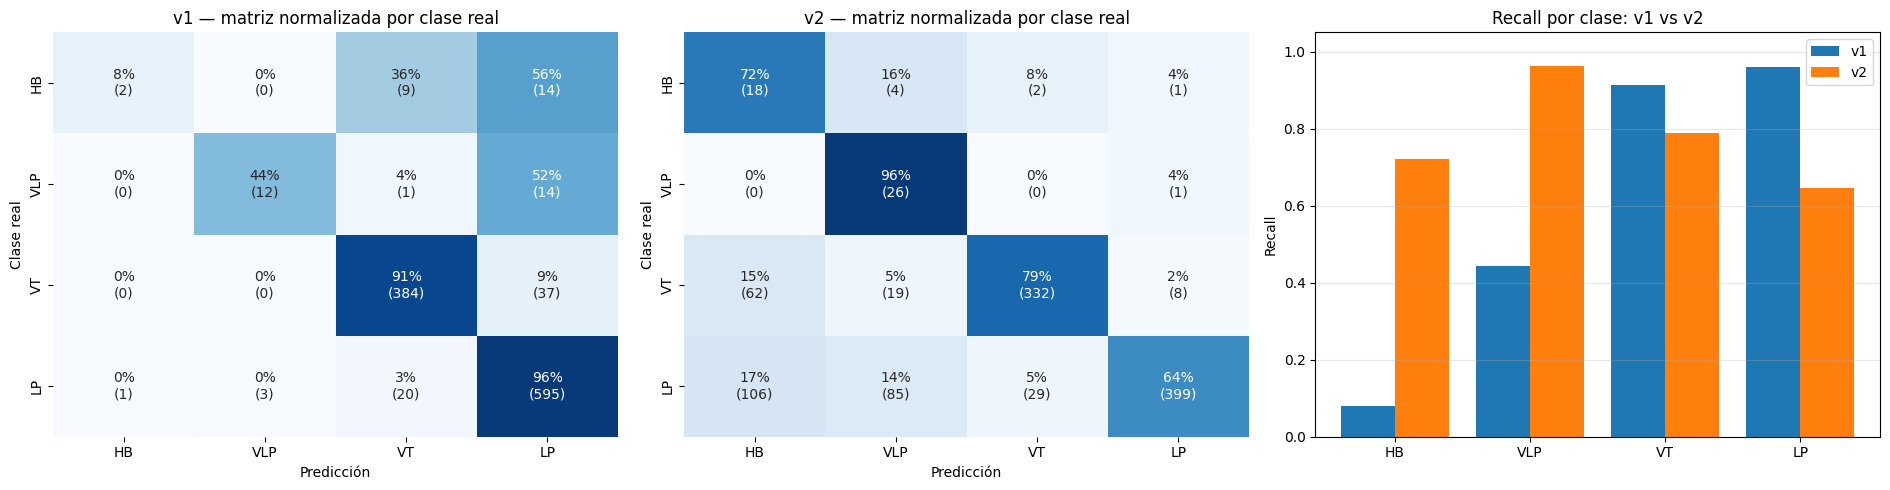

In [30]:
def plot_cm(ax, cm, title):
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    annot = np.array([[f"{cm_norm[i, j]:.0%}\n({cm[i, j]})" for j in range(NUM_CLASSES)]
                      for i in range(NUM_CLASSES)])
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")


fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_cm(axes[0], BASELINE_CM, "v1 — matriz normalizada por clase real")
plot_cm(axes[1], cm_new, "v2 — matriz normalizada por clase real")

x_pos = np.arange(NUM_CLASSES)
axes[2].bar(x_pos - 0.2, r0, width=0.4, label="v1")
axes[2].bar(x_pos + 0.2, r1, width=0.4, label="v2")
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(CLASS_NAMES)
axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel("Recall")
axes[2].set_title("Recall por clase: v1 vs v2")
axes[2].legend()
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
from scipy.special import softmax
from sklearn.metrics import f1_score, average_precision_score


@torch.no_grad()
def get_logits(loader):
    model.eval()
    outs, ys = [], []
    for x, lengths, labels in loader:
        outs.append(model(x.to(device), lengths.to(device)).cpu())
        ys.append(labels)
    return torch.cat(outs).numpy(), torch.cat(ys).numpy()


val_logits, val_y = get_logits(val_loader)
test_logits, test_y = get_logits(test_loader)

In [32]:
test_probs = softmax(test_logits, axis=1)
ap = [average_precision_score(test_y == c, test_probs[:, c]) for c in range(NUM_CLASSES)]
base = [(test_y == c).mean() for c in range(NUM_CLASSES)]
display(pd.DataFrame({"AP (test)": ap, "Azar": base}, index=CLASS_NAMES).round(3))

,AP (test),Azar
HB,0.258,0.023
VLP,0.841,0.025
VT,0.946,0.386
LP,0.958,0.567


tau elegido en validación: 0.55


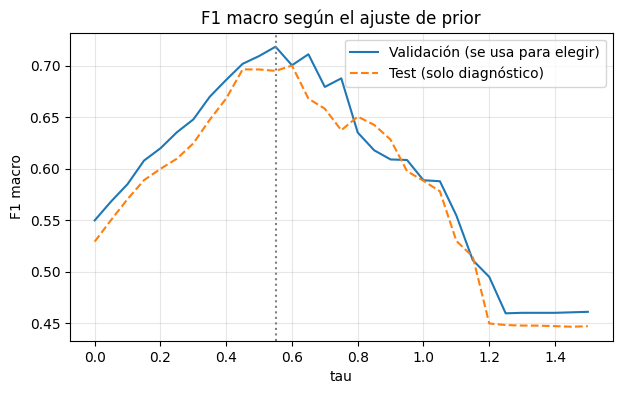

In [33]:
log_prior = np.log(counts / counts.sum())
taus = np.linspace(0, 1.5, 31)


def macro_f1_at(logits, labels, tau):
    pred = (logits + tau * log_prior).argmax(axis=1)
    return f1_score(labels, pred, average="macro", zero_division=0)


f1_val = [macro_f1_at(val_logits, val_y, t) for t in taus]
f1_test = [macro_f1_at(test_logits, test_y, t) for t in taus]
best_tau = taus[int(np.argmax(f1_val))]
print(f"tau elegido en validación: {best_tau:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(taus, f1_val, label="Validación (se usa para elegir)")
plt.plot(taus, f1_test, label="Test (solo diagnóstico)", linestyle="--")
plt.axvline(best_tau, color="gray", linestyle=":")
plt.xlabel("tau")
plt.ylabel("F1 macro")
plt.title("F1 macro según el ajuste de prior")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

,Accuracy,F1 macro,Recall HB,Recall VLP,Recall VT,Recall LP,Prec. HB,Prec. VLP,Prec. VT,Prec. LP
v1,0.909,0.641,0.08,0.444,0.912,0.961,0.667,0.800,0.928,0.902
v2,0.710,0.529,0.72,0.963,0.789,0.645,0.097,0.194,0.915,0.976
v2 + ajuste (tau=0.55),0.889,0.695,0.28,0.778,0.898,0.913,0.269,0.618,0.896,0.926


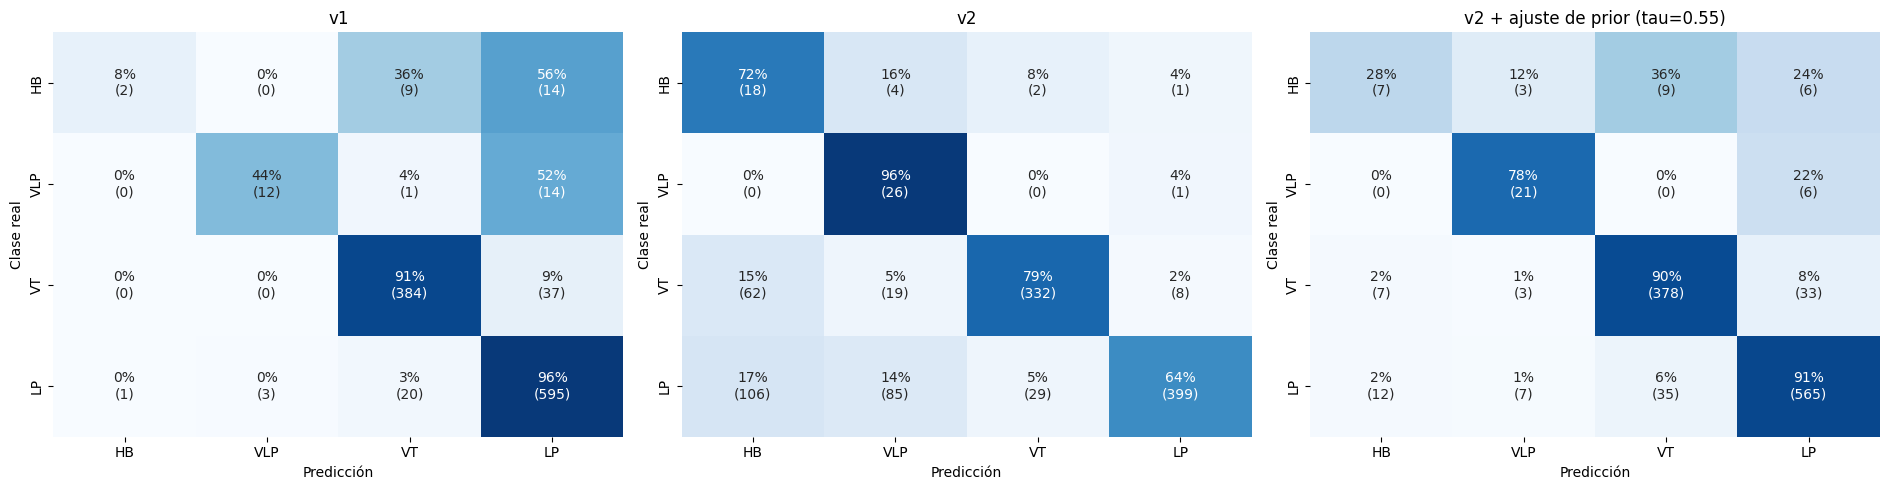

In [34]:
pred_adj = (test_logits + best_tau * log_prior).argmax(axis=1)
cm_adj = confusion_matrix(test_y, pred_adj, labels=range(NUM_CLASSES))

rows = {}
for name, cm in [("v1", BASELINE_CM), ("v2", cm_new), (f"v2 + ajuste (tau={best_tau:.2f})", cm_adj)]:
    p, r, f, a = metrics_from_cm(cm)
    rows[name] = {"Accuracy": a, "F1 macro": f.mean(),
                  **{f"Recall {c}": r[i] for i, c in enumerate(CLASS_NAMES)},
                  **{f"Prec. {c}": p[i] for i, c in enumerate(CLASS_NAMES)}}
display(pd.DataFrame(rows).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_cm(axes[0], BASELINE_CM, "v1")
plot_cm(axes[1], cm_new, "v2")
plot_cm(axes[2], cm_adj, f"v2 + ajuste de prior (tau={best_tau:.2f})")
plt.tight_layout()
plt.show()